# Partie 1.1 : analyse exploratoire et découpage des données

Ce notebook prépare les données une seule fois pour tout le projet :

- il compte les images de chaque classe et en affiche des exemples ;
- il cherche les images en double (la même feuille tournée ou retournée) pour éviter les fuites de données ;
- il fait le découpage 70 % / 15 % / 15 % (stratifié, graine 42) et l'enregistre dans `data/splits.csv` ;
- il calcule les statistiques de normalisation sur le train ;
- il prépare le jeu hors-distribution de la partie 4.

Tous les autres notebooks relisent `data/splits.csv`. On ne le régénère plus une fois les entraînements commencés.

- On ajoute le dossier du projet au chemin Python pour importer notre code (`src/`).
- `config` contient les chemins, la classe M choisie et le GPU utilisé.
- `set_seed(42)` fixe le hasard : on obtient les mêmes résultats à chaque exécution.
- La dernière ligne affiche la machine utilisée (à noter dans le rapport).

In [18]:
import sys
from pathlib import Path

# dossier du projet, pour pouvoir importer src/
sys.path.insert(0, str(Path.cwd().parent))   

from src import config as C
C.set_seed(42)
print(C.describe_env())

Python 3.12.10, torch 2.6.0+cu124, torchvision 0.21.0+cu124
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 4080 Laptop GPU
CPU : 13th Gen Intel(R) Core(TM) i7-13650HX (20 coeurs logiques)


- Imports des bibliothèques et de nos fonctions (`data`, `dedup` pour les doublons, `viz` pour les grilles d'images).
- `SEUIL = 4` : deux images dont les hash diffèrent de 4 bits ou moins (sur 64) sont considérées comme la même feuille. On vérifie ce choix plus bas.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib, shutil
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

from src import data as D, dedup, viz
from src.metrics import savefig

# nombre de bits maximum entre deux hash pour dire que c'est la même feuille
SEUIL = 4   

## Les données

- `ensure_raw_data()` télécharge PlantVillage depuis Kaggle et copie les 10 dossiers de tomate dans `data/raw/`.
- On prend la version originale « color » et pas la version « Augmented » de Kaggle, qui contient déjà des copies tournées des mêmes feuilles.
- On liste toutes les images avec leur classe. Le chemin est gardé en relatif (`raw/...`) pour que le fichier marche sur n'importe quel ordinateur.
- On affiche le nombre d'images par classe : c'est le chiffre exact à mettre dans le rapport.

In [20]:
color_dir = D.ensure_raw_data()
print("Source : Kaggle", C.KAGGLE_DATASET, "(PlantVillage original, dossier color)")

lignes = []
for classe in D.CLASSES:
    for fichier in D.list_images(C.RAW_DIR / classe):
        lignes.append({"path": "raw/" + classe + "/" + fichier.name, "class": classe})
df = pd.DataFrame(lignes)
df = df.sort_values(["class", "path"]).reset_index(drop=True)

effectifs = df["class"].value_counts()
print("Nombre total d'images :", len(df))
for classe in D.CLASSES:
    print(D.short(classe), ":", effectifs[classe])

Source : Kaggle abdallahalidev/plantvillage-dataset (PlantVillage original, dossier color)
Nombre total d'images : 18160
Bacterial_spot : 2127
Early_blight : 1000
Late_blight : 1909
Leaf_Mold : 952
Septoria_leaf_spot : 1771
Spider_mites : 1676
Target_Spot : 1404
Yellow_Leaf_Curl : 5357
Mosaic_virus : 373
healthy : 1591


- On met les noms courts des classes et leurs effectifs dans deux listes, puis on trace un diagramme en barres horizontales.
- Le rapport entre la plus grande et la plus petite classe mesure le déséquilibre. Il justifie l'usage du F1 macro (voir plus bas).

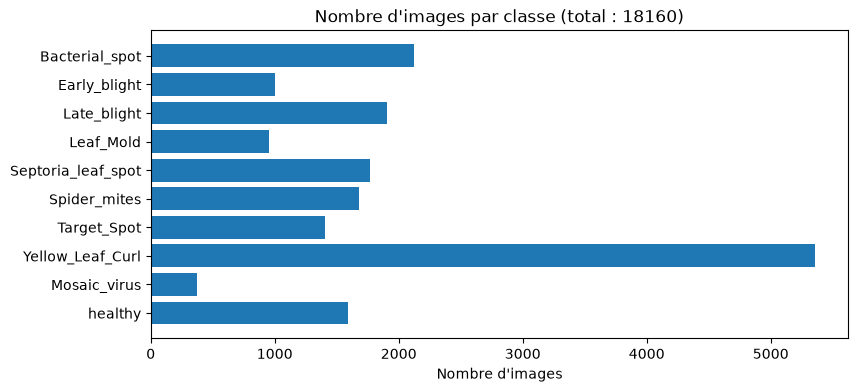

La plus grande classe a 14.4 fois plus d'images que la plus petite.


In [21]:
noms = []
nombres = []
for classe in D.CLASSES:
    noms.append(D.short(classe))
    nombres.append(effectifs[classe])

plt.figure(figsize=(9, 4))
plt.barh(noms, nombres)
plt.gca().invert_yaxis()
plt.xlabel("Nombre d'images")
plt.title("Nombre d'images par classe (total : " + str(len(df)) + ")")
savefig("00_effectifs.png")
plt.show()

rapport = max(nombres) / min(nombres)
print("La plus grande classe a", round(rapport, 1), "fois plus d'images que la plus petite.")

- On tire 5 images au hasard dans chaque classe et on les affiche.
- On remarque que toutes les photos ont le même fond uni de laboratoire. On y reviendra en partie 6 (biais de fond).

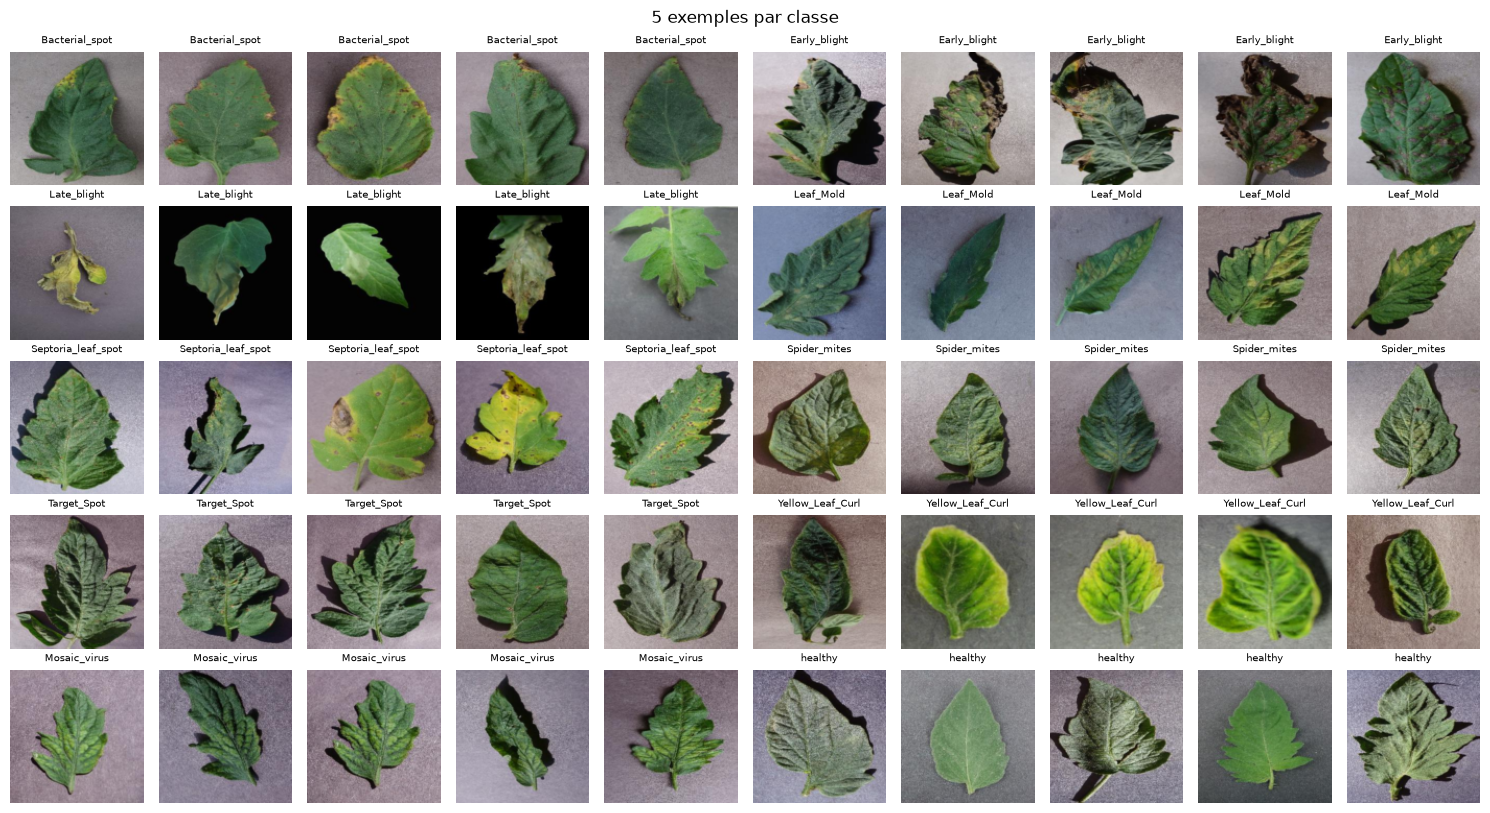

In [22]:
images, titres = [], []
for classe in D.CLASSES:
    exemples = df[df["class"] == classe].sample(5, random_state=42)
    for chemin in exemples["path"]:
        images.append(D.read_rgb(C.resolve(chemin), 128))
        titres.append(D.short(classe))
viz.image_grid(images, titres, ncols=10, size=1.5, path=C.FIG_DIR / "00_exemples.png", suptitle="5 exemples par classe")

## Vérification anti-fuite : recherche des doublons

Certaines versions de PlantVillage contiennent la même feuille plusieurs fois (tournée ou retournée). Si une copie est dans le train et une autre dans le test, le test devient trop facile : c'est une fuite de données.

Méthode :

1. pour chaque image on calcule un **hash perceptuel** (pHash), une empreinte de 64 bits qui change peu si l'image est compressée ou redimensionnée ;
2. on le calcule aussi pour les 8 versions de l'image (4 rotations, avec et sans miroir) ;
3. deux images sont la même feuille si leurs empreintes diffèrent de 4 bits au plus ;
4. les images qui sont la même feuille forment un **groupe** (`leaf_group`), et un groupe ira entièrement dans un seul split.

- On calcule les 8 hash de chaque image, puis on les sauvegarde pour ne pas les recalculer la prochaine fois (c'est l'étape la plus longue).
- Le md5 détecte en plus les fichiers copiés à l'identique.

In [23]:
fichier_hash = C.DATA_DIR / ("phash8_" + str(len(df)) + ".npy")
if fichier_hash.exists():
    H = np.load(fichier_hash)
else:
    chemins = []
    for p in df["path"]:
        chemins.append(C.resolve(p))
    H = dedup.compute_hashes(chemins)
    np.save(fichier_hash, H)
print("Hash calculés :", H.shape, "(une ligne par image, 8 versions par image)")

md5 = []
for p in df["path"]:
    contenu = open(C.resolve(p), "rb").read()
    md5.append(hashlib.md5(contenu).hexdigest())
df["md5"] = md5
print("Fichiers strictement identiques :", len(df) - df["md5"].nunique())

Hash calculés : (18160, 8) (une ligne par image, 8 versions par image)
Fichiers strictement identiques : 14


- On cherche toutes les paires d'images proches (jusqu'à 8 bits d'écart).
- On compte combien de paires on trouverait avec chaque seuil de 0 à 8.
- Si le nombre augmente très vite après 4, c'est qu'on commence à attraper des feuilles différentes mais qui se ressemblent. Ce tableau sert à justifier le seuil de 4.
- `paires` garde seulement les paires au seuil choisi.

In [24]:
# liste de (image i, image j, distance)
paires_8 = dedup.find_pairs(H, threshold=8)     

print("Nombre de paires selon le seuil :")
for s in range(9):
    compte = 0
    for (i, j, d) in paires_8:
        if d <= s:
            compte += 1
    print("  distance <=", s, "bits :", compte, "paires")

paires = []
for (i, j, d) in paires_8:
    if d <= SEUIL:
        paires.append((i, j, d))

Nombre de paires selon le seuil :
  distance <= 0 bits : 14 paires
  distance <= 1 bits : 14 paires
  distance <= 2 bits : 24 paires
  distance <= 3 bits : 24 paires
  distance <= 4 bits : 97 paires
  distance <= 5 bits : 97 paires
  distance <= 6 bits : 854 paires
  distance <= 7 bits : 854 paires
  distance <= 8 bits : 6631 paires


- On affiche 20 paires au hasard, côte à côte.
- Vérification à l'oeil : les paires de même classe doivent être la même feuille (sinon baisser `SEUIL`). Les paires entre deux classes différentes peuvent être de simples ressemblances (voir la cellule suivante).

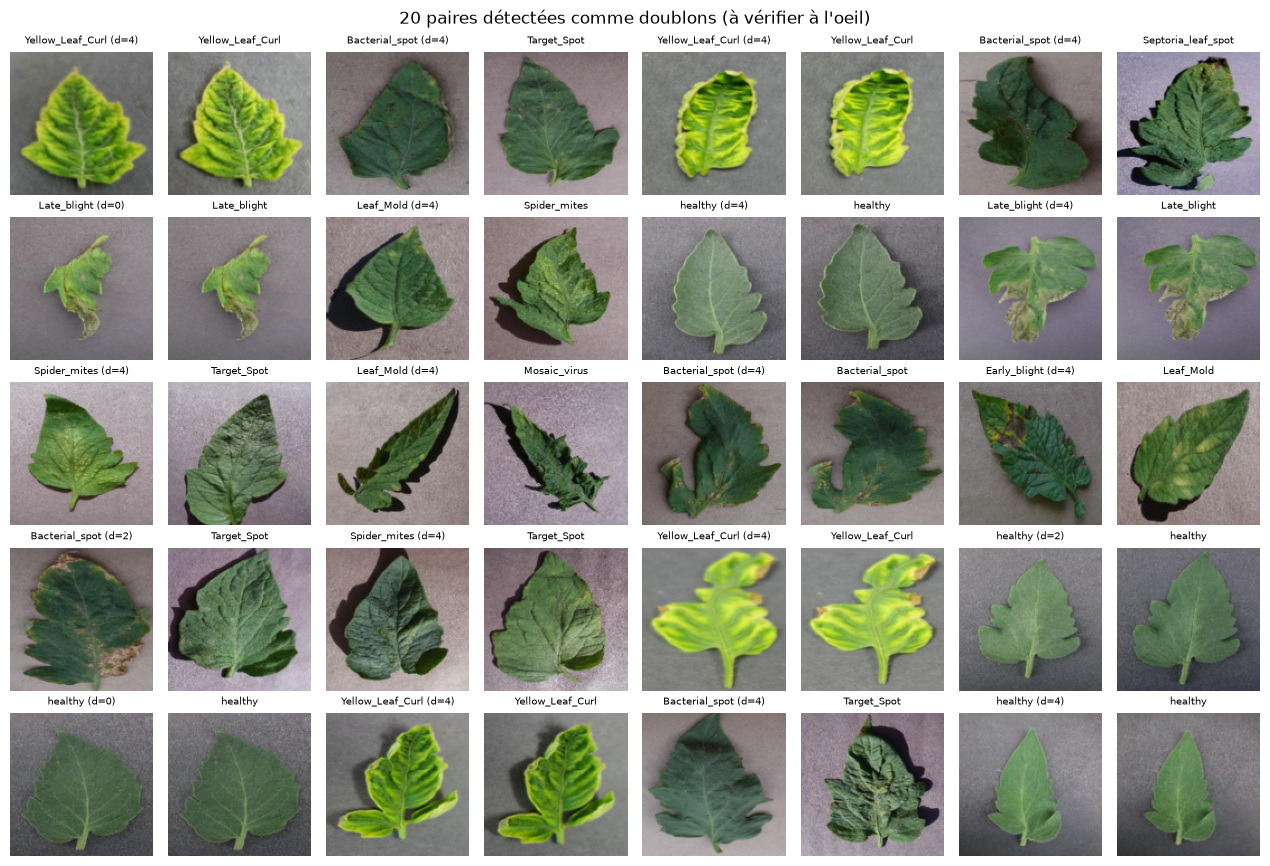

In [25]:
ordre = np.random.default_rng(42).permutation(len(paires))[:20]
images, titres = [], []
for k in ordre:
    i, j, d = paires[k]
    images.append(D.read_rgb(C.resolve(df["path"][i]), 128))
    images.append(D.read_rgb(C.resolve(df["path"][j]), 128))
    titres.append(D.short(df["class"][i]) + " (d=" + str(d) + ")")
    titres.append(D.short(df["class"][j]))
viz.image_grid(images, titres, ncols=8, size=1.6, path=C.FIG_DIR / "00_paires_doublons.png",
               suptitle="20 paires détectées comme doublons (à vérifier à l'oeil)")

- On regroupe les doublons : si A ressemble à B et B à C, alors A, B et C sont dans le même groupe.
- On affiche le résumé des doublons.
- On sépare les paires de même classe et les paires entre deux classes différentes. En regardant la grille, les paires de même classe sont bien la même feuille. Les paires entre deux classes sont en général des feuilles différentes qui ont la même silhouette sur le fond gris : ce sont des fausses alertes du pHash.
- Ces fausses alertes ne posent pas de problème pour la fuite : elles mettent juste deux feuilles différentes dans le même split, ce qui est plus prudent.
- Un groupe énorme voudrait dire que le seuil relie des feuilles différentes en chaîne.

In [26]:
df["leaf_group"] = dedup.groups_from_pairs(len(df), paires)
taille_groupes = df.groupby("leaf_group").size()
classes_par_groupe = df.groupby("leaf_group")["class"].nunique()

meme_classe = 0
for (i, j, d) in paires:
    if df["class"][i] == df["class"][j]:
        meme_classe += 1

print("Paires de doublons trouvées :", len(paires))
print("Paires de même classe :", meme_classe, "| paires entre deux classes différentes :", len(paires) - meme_classe)
print("Groupes de plus d'une image :", (taille_groupes > 1).sum())
print("Images concernées :", taille_groupes[taille_groupes > 1].sum())
print("Taille du plus gros groupe :", taille_groupes.max())
print("Groupes qui mélangent deux classes :", (classes_par_groupe > 1).sum())
if taille_groupes.max() > 50:
    print("ATTENTION : groupe très gros, le seuil est sans doute trop haut.")

Paires de doublons trouvées : 97
Paires de même classe : 73 | paires entre deux classes différentes : 24
Groupes de plus d'une image : 94
Images concernées : 191
Taille du plus gros groupe : 4
Groupes qui mélangent deux classes : 21


## Découpage 70 / 15 / 15

`StratifiedGroupKFold` coupe les données en 20 parts d'environ 5 %. Il respecte deux règles : chaque groupe reste dans une seule part, et chaque part garde les mêmes proportions de classes (stratification). On prend 3 parts pour le test (15 %), 3 pour la validation (15 %) et 14 pour le train (70 %).

- On numérote chaque part de 0 à 19, puis : parts 0 à 2 vers le test, 3 à 5 vers la validation, le reste vers le train.
- On vérifie qu'aucun groupe n'est coupé entre deux splits (sinon le programme s'arrête avec `assert`).
- Le tableau montre, pour chaque classe, la part en train, val et test : chaque ligne doit être proche de 0,70 / 0,15 / 0,15.

In [27]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=42)
part = np.zeros(len(df), dtype=int)
k = 0
for _, indices in sgkf.split(df, df["class"], groups=df["leaf_group"]):
    # numéro de la part (0 à 19) de chaque image
    part[indices] = k          
    k += 1

df["split"] = "train"
 # parts 0, 1, 2
df.loc[part < 3, "split"] = "test"    
 # parts 3, 4, 5
df.loc[(part >= 3) & (part < 6), "split"] = "val"    

splits_par_groupe = df.groupby("leaf_group")["split"].nunique()
groupes_partages = (splits_par_groupe > 1).sum()
print("Groupes présents dans plusieurs splits :", groupes_partages)
assert groupes_partages == 0

print(df["split"].value_counts(normalize=True).round(3))
proportions = pd.crosstab(df["class"], df["split"], normalize="index")
proportions[["train", "val", "test"]].round(3)

Groupes présents dans plusieurs splits : 0
split
train    0.70
test     0.15
val      0.15
Name: proportion, dtype: float64


split,train,val,test
class,,,
Tomato___Bacterial_spot,0.700,0.150,0.150
Tomato___Early_blight,0.700,0.150,0.150
Tomato___Late_blight,0.701,0.149,0.150
Tomato___Leaf_Mold,0.699,0.151,0.150
Tomato___Septoria_leaf_spot,0.700,0.150,0.150
Tomato___Spider_mites Two-spotted_spider_mite,0.700,0.150,0.150
Tomato___Target_Spot,0.698,0.151,0.151
Tomato___Tomato_Yellow_Leaf_Curl_Virus,0.700,0.150,0.150
Tomato___Tomato_mosaic_virus,0.700,0.153,0.147


- Contre-vérification : pour chaque image du test, on la compare à toutes les versions (rotations, miroirs) des images du train. Même chose pour val/train et test/val.
- On doit trouver 0 image proche et 0 fichier identique. C'est la preuve anti-fuite demandée.

In [28]:
indices_train = np.where(df["split"] == "train")[0]
indices_val = np.where(df["split"] == "val")[0]
indices_test = np.where(df["split"] == "test")[0]

def verifier(nom_a, idx_a, nom_b, idx_b):

    # distance de chaque image de A à chaque image de B
    distances = dedup.min_distances(H[idx_a], H[idx_b])     
    proches = (distances <= SEUIL).sum()
    md5_communs = len(set(df["md5"][idx_a]) & set(df["md5"][idx_b]))
    print(nom_a, "/", nom_b, ":", proches, "images proches,", md5_communs, "fichiers identiques")
    assert proches == 0 and md5_communs == 0

verifier("test", indices_test, "train", indices_train)
verifier("val", indices_val, "train", indices_train)
verifier("test", indices_test, "val", indices_val)
print("Résultat : 0 hash commun entre train, validation et test.")

test / train : 0 images proches, 0 fichiers identiques
val / train : 0 images proches, 0 fichiers identiques
test / val : 0 images proches, 0 fichiers identiques
Résultat : 0 hash commun entre train, validation et test.


- On enregistre le découpage dans `data/splits.csv` (colonnes : chemin, classe, groupe, split).

In [29]:
df[["path", "class", "leaf_group", "split"]].to_csv(C.SPLITS_CSV, index=False)
print("Fichier écrit :", C.SPLITS_CSV)

Fichier écrit : C:\Users\limam\Downloads\notebooks-20261019T220927Z-1-001\notebooks\diagnoculture\data\splits.csv


## Normalisation

- Pour les modèles entraînés **de zéro**, on calcule la moyenne et l'écart-type de chaque canal (R, G, B) **sur le train seulement**. Si on utilisait aussi la validation ou le test, de l'information de ces images entrerait dans l'entraînement.
- Pour le **transfer learning**, on garde les valeurs d'ImageNet, car le modèle pré-entraîné a appris avec elles.
- Pour les **auto-encodeurs**, pas de normalisation : les pixels restent entre 0 et 1.

- On charge les images du train en 128×128.
- Pour chaque image, on calcule la moyenne de chaque canal (R, G, B) et la moyenne des carrés. Toutes les images ont la même taille, donc la moyenne des moyennes donne la moyenne globale.
- Écart-type : $\sigma = \sqrt{E[x^2] - \mu^2}$.
- On enregistre le résultat dans `results/norm_stats.json`, relu par le notebook 01.
- On compare avec les valeurs ImageNet : les moyennes sont proches, mais les écarts-types de nos images sont plus petits (fond uni, couleurs peu variées). C'est une raison de plus d'utiliser nos propres statistiques pour les modèles de zéro.

In [30]:
train = df[df["split"] == "train"]
chemins = []
for p in train["path"]:
    chemins.append(C.resolve(p))

# toutes les images du train en 128 x 128
images_train = D.load_cache(chemins, 128) 

moyennes = []
carres = []
for img in images_train:
    x = img / 255.0                              # pixels entre 0 et 1
    moyennes.append(x.mean(axis=(0, 1)))         # moyenne de R, G, B sur l'image
    carres.append((x ** 2).mean(axis=(0, 1)))
moyenne = np.mean(moyennes, axis=0)
ecart_type = np.sqrt(np.mean(carres, axis=0) - moyenne ** 2)

C.save_json({"mean": moyenne.round(5).tolist(), "std": ecart_type.round(5).tolist()}, C.NORM_JSON)
print("Moyenne (R, G, B)    :", moyenne.round(4), " ImageNet :", C.IMAGENET_MEAN)
print("Écart-type (R, G, B) :", ecart_type.round(4), " ImageNet :", C.IMAGENET_STD)

Moyenne (R, G, B)    : [0.4503 0.4659 0.4008]  ImageNet : [0.485, 0.456, 0.406]
Écart-type (R, G, B) : [0.1742 0.1517 0.1909]  ImageNet : [0.229, 0.224, 0.225]


## Déséquilibre des classes

Les classes n'ont pas le même nombre d'images. Un modèle qui ignore la classe rare (mosaïque) perdrait très peu d'accuracy. On fait donc deux choses :

- une perte pondérée : chaque classe reçoit un poids $w_c = \frac{N}{K \times n_c}$ ($N$ images, $K$ classes, $n_c$ images de la classe), donc une erreur sur une classe rare coûte plus cher ;
- le **F1 macro** comme métrique principale : c'est la moyenne des F1 de chaque classe, toutes les classes comptent pareil.

- Calcul des poids de chaque classe à partir du train. Les notebooks d'entraînement refont exactement le même calcul.

In [31]:
y_train = []
for classe in train["class"]:
    y_train.append(D.CLASSES.index(classe))
y_train = np.array(y_train)

poids = D.class_weights(y_train, len(D.CLASSES))     # w_c = N / (K x n_c)
for k in range(len(D.CLASSES)):
    print(D.short(D.CLASSES[k]), ": ", (y_train == k).sum(), "images, poids", round(float(poids[k]), 3))

Bacterial_spot :  1489 images, poids 0.854
Early_blight :  700 images, poids 1.816
Late_blight :  1338 images, poids 0.95
Leaf_Mold :  665 images, poids 1.911
Septoria_leaf_spot :  1240 images, poids 1.025
Spider_mites :  1173 images, poids 1.084
Target_Spot :  980 images, poids 1.297
Yellow_Leaf_Curl :  3750 images, poids 0.339
Mosaic_virus :  261 images, poids 4.87
healthy :  1115 images, poids 1.14


## Jeu hors-distribution (pour la partie 4)

- **Autres espèces de PlantVillage** (pomme, vigne, pomme de terre...) : on en prend environ 600. On sépare les espèces en deux moitiés : `calib` sert à régler le système hybride (ce ne sont pas des images du test), `eval` sert à l'évaluer.
- **Nos photos** (au moins 30) à mettre dans `data/ood/photos/`, dans les sous-dossiers `tomate_fond_naturel`, `autres_plantes`, `mains`, `sol_objets`.
- **Feuilles de tomate sur le terrain** : nous n'avons pas eu accès à des plants de tomate. Nous utilisons donc 62 photos de feuilles de tomate prises au champ, issues du jeu public **PlantDoc** (Singh et al., 2020, licence CC BY 4.0), rangées dans `data/ood/terrain_plantdoc/`. 7 images qui n'étaient pas des photos (diapositives, montages avec texte) ont été retirées. Ce ne sont pas nos photos : elles s'ajoutent aux 30 photos personnelles et sont citées dans le rapport.

- On liste les dossiers qui ne sont pas de la tomate et on tire au hasard la moitié des espèces pour `calib`.
- On copie environ 600 images de ces espèces dans `data/ood/plantvillage_autres/`.
- On ajoute nos photos personnelles (la catégorie est le nom du sous-dossier), puis les photos de terrain PlantDoc.
- Tout est enregistré dans `data/ood.csv`.
- Cette cellule peut être relancée seule quand les photos sont ajoutées : elle ne touche pas au découpage.

In [32]:
autres = []
for d in color_dir.iterdir():
    if d.is_dir() and not d.name.startswith("Tomato"):
        autres.append(d.name)
autres = sorted(autres)

especes = []
for a in autres:
    espece = a.split("___")[0]
    if espece not in especes:
        especes.append(espece)
especes = sorted(especes)

rng = np.random.default_rng(42)
especes_calib = rng.choice(especes, size=len(especes) // 2, replace=False).tolist()
par_classe = 600 // len(autres)

lignes = []
for a in autres:
    espece = a.split("___")[0]
    if espece in especes_calib:
        moitie = "calib"
    else:
        moitie = "eval"
    fichiers = D.list_images(color_dir / a)
    for f in rng.choice(fichiers, size=min(par_classe, len(fichiers)), replace=False):
        destination = C.OOD_DIR / "plantvillage_autres" / a / f.name
        destination.parent.mkdir(parents=True, exist_ok=True)
        if not destination.exists():
            shutil.copy(f, destination)
        lignes.append({"path": "ood/plantvillage_autres/" + a + "/" + f.name, "source": "plantvillage_autres",
                       "category": espece, "ood_split": moitie})

for f in D.list_images(C.OOD_DIR / "photos"):
    lignes.append({"path": "ood/photos/" + f.parent.name + "/" + f.name, "source": "photos",
                   "category": f.parent.name, "ood_split": "eval"})

# Feuilles de tomate photographiées sur le terrain (jeu public PlantDoc, licence CC BY 4.0)
for f in D.list_images(C.OOD_DIR / "terrain_plantdoc"):
    lignes.append({"path": "ood/terrain_plantdoc/" + f.parent.name + "/" + f.name, "source": "plantdoc",
                   "category": "tomate_terrain_plantdoc", "ood_split": "eval"})

ood = pd.DataFrame(lignes)
ood.to_csv(C.OOD_CSV, index=False)
nb_photos = (ood["source"] == "photos").sum()
nb_plantdoc = (ood["source"] == "plantdoc").sum()
print("Espèces pour la calibration :", sorted(especes_calib))
print(len(ood), "images hors-distribution, dont", nb_photos, "photos personnelles et", nb_plantdoc, "photos de terrain PlantDoc")
if nb_photos < 30:
    print("Il manque des photos personnelles (au moins 30 demandées) : les ajouter dans data/ood/photos/ puis relancer cette cellule.")

Espèces pour la calibration : ['Apple', 'Grape', 'Orange', 'Peach', 'Raspberry', 'Squash']
650 images hors-distribution, dont 0 photos personnelles et 62 photos de terrain PlantDoc
Il manque des photos personnelles (au moins 30 demandées) : les ajouter dans data/ood/photos/ puis relancer cette cellule.


## Bilan : les trois points d'attention de l'énoncé

**1. Fuite de données (même feuille sous plusieurs formes).**

- On a pris la version originale « color » de PlantVillage (Mohanty et al.), et pas la version « Augmented » de Kaggle, qui contient déjà des rotations et des retournements des mêmes feuilles.
- On a quand même vérifié : pHash de chaque image et de ses 8 versions (4 rotations, avec et sans miroir), puis comparaison de toutes les paires. Résultat : 14 fichiers strictement identiques et 97 paires proches (4 bits ou moins), qui forment 94 groupes (191 images, au plus 4 images par groupe).
- Chaque groupe est placé entièrement dans un seul split grâce à `StratifiedGroupKFold` (70 / 15 / 15, stratifié, graine 42).
- Preuve finale : 0 image proche et 0 fichier identique entre train, validation et test, en comparant chaque image à toutes les rotations et retournements des images des autres splits.
- Les augmentations (retournements, rotations de 90°) sont faites à la volée et **seulement sur le train**, après le découpage : elles ne créent pas de fuite.

**2. Biais de fond.**

- On voit dès les exemples ci-dessus que toutes les photos ont le même fond uni de laboratoire. Ce risque est analysé dans la partie 6 (notebook 06) : cartes Grad-CAM, puis test chiffré où l'on remplace le fond par du noir, du bruit ou du sol pour mesurer la chute de performance. La partie 4 le teste aussi avec nos photos de feuilles de tomate sur fond naturel.

**3. Déséquilibre des classes.**

- La plus grande classe (Yellow_Leaf_Curl, 5 357 images) a 14,4 fois plus d'images que la plus petite (Mosaic_virus, 373 images).
- Pendant l'entraînement : perte pondérée, avec un poids de 4,87 pour la mosaïque contre 0,34 pour Yellow_Leaf_Curl.
- Pour l'évaluation : le **F1 macro** est la métrique principale (toutes les classes comptent pareil), toujours accompagnée du rappel par classe et de la matrice de confusion. L'accuracy seule n'est jamais utilisée pour conclure.